# Week 3: The Cleaning Sprint

## Objective
To investigate data-quality issues in the IPL datasets and apply suitable preprocessing methods.

## Tasks
1. Investigate missing values.
2. Check data types and unusual values.
3. Detect potential outliers using boxplots and the IQR method.
4. Apply appropriate cleaning methods where justified.
5. Preserve the original datasets for comparison.

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

data_folder = r"D:\DSD\College\DSV\Project\archive\moneyball\datasets"

auction = pd.read_excel(os.path.join(data_folder, "Auction.xlsx"))
batsmen = pd.read_excel(os.path.join(data_folder, "Top_100_batsman.xlsx"))
bowlers = pd.read_excel(os.path.join(data_folder, "Top_100_bowlers.xlsx"))
matches = pd.read_csv(os.path.join(data_folder, "matches.csv"))

print("All original datasets loaded successfully!")

All original datasets loaded successfully!


In [2]:
auction_clean = auction.copy()
batsmen_clean = batsmen.copy()
bowlers_clean = bowlers.copy()
matches_clean = matches.copy()

print("Working copies created successfully!")

Working copies created successfully!


In [3]:
datasets_clean = {
    "Auction": auction_clean,
    "Top 100 Batsmen": batsmen_clean,
    "Top 100 Bowlers": bowlers_clean,
    "Matches": matches_clean
}

for name, data in datasets_clean.items():
    print("\n", name)
    print("Missing values:", data.isnull().sum().sum())
    print(data.isnull().sum()[data.isnull().sum() > 0])


 Auction
Missing values: 0
Series([], dtype: int64)

 Top 100 Batsmen
Missing values: 0
Series([], dtype: int64)

 Top 100 Bowlers
Missing values: 0
Series([], dtype: int64)

 Matches
Missing values: 656
city                 7
winner               4
player_of_match      4
umpire1              2
umpire2              2
umpire3            637
dtype: int64


In [4]:
print("Umpire 3 value counts:")
print(matches_clean["umpire3"].value_counts(dropna=False).head(10))

print("\nSample matches with missing umpire3:")
display(
    matches_clean[matches_clean["umpire3"].isnull()]
    [["season", "date", "team1", "team2", "umpire1", "umpire2", "umpire3"]]
    .head(10)
)

Umpire 3 value counts:
umpire3
NaN                637
Nitin Menon         10
O Nandan            10
C Shamshuddin       10
Anil Chaudhary       9
S Ravi               8
Vineet Kulkarni      8
Anil Dandekar        7
Yeshwant Barde       7
Bruce Oxenford       7
Name: count, dtype: int64

Sample matches with missing umpire3:


,season,date,team1,team2,umpire1,umpire2,umpire3
0,2017,4/5/2017,Sunrisers Hyderabad,Royal Challengers Bangalore,AY Dandekar,NJ Llong,NaN
1,2017,4/6/2017,Mumbai Indians,Rising Pune Supergiant,A Nand Kishore,S Ravi,NaN
2,2017,4/7/2017,Gujarat Lions,Kolkata Knight Riders,Nitin Menon,CK Nandan,NaN
3,2017,4/8/2017,Rising Pune Supergiant,Kings XI Punjab,AK Chaudhary,C Shamshuddin,NaN
4,2017,4/8/2017,Royal Challengers Bangalore,Delhi Daredevils,NaN,NaN,NaN
5,2017,4/9/2017,Gujarat Lions,Sunrisers Hyderabad,A Deshmukh,NJ Llong,NaN
6,2017,4/9/2017,Kolkata Knight Riders,Mumbai Indians,Nitin Menon,CK Nandan,NaN
7,2017,4/10/2017,Royal Challengers Bangalore,Kings XI Punjab,AK Chaudhary,C Shamshuddin,NaN
8,2017,4/11/2017,Delhi Daredevils,Rising Pune Supergiant,AY Dandekar,S Ravi,NaN
9,2017,4/12/2017,Sunrisers Hyderabad,Mumbai Indians,Nitin Menon,CK Nandan,NaN


In [5]:
print("Data types in Matches:")
print(matches_clean.dtypes)

print("\nMissing values in other datasets:")
for name in ["Auction", "Top 100 Batsmen", "Top 100 Bowlers"]:
    data = datasets_clean[name]
    print(f"{name}: {data.isnull().sum().sum()} missing values")

Data types in Matches:
id                 int64
season             int64
city                 str
date                 str
team1                str
team2                str
toss_winner          str
toss_decision        str
result               str
dl_applied         int64
winner               str
win_by_runs        int64
win_by_wickets     int64
player_of_match      str
venue                str
umpire1              str
umpire2              str
umpire3              str
dtype: object

Missing values in other datasets:
Auction: 0 missing values
Top 100 Batsmen: 0 missing values
Top 100 Bowlers: 0 missing values


## 4. Handling Missing Values

The Auction, Top 100 Batsmen, and Top 100 Bowlers datasets contain no missing values.

The Matches dataset contains missing values in city, winner, player_of_match, umpire1, umpire2, and umpire3.

We will preserve useful match records and handle missing values according to the meaning of each column.

In [6]:
print("Missing values before cleaning:")
print(matches_clean.isnull().sum())

print("\nTotal rows before cleaning:", len(matches_clean))

Missing values before cleaning:
id                   0
season               0
city                 7
date                 0
team1                0
team2                0
toss_winner          0
toss_decision        0
result               0
dl_applied           0
winner               4
win_by_runs          0
win_by_wickets       0
player_of_match      4
venue                0
umpire1              2
umpire2              2
umpire3            637
dtype: int64

Total rows before cleaning: 756


### Missing Value Strategy

- `umpire3`: Missing values may be retained because a third umpire may not have been recorded.
- `city`: We will investigate whether the venue can help identify the missing city.
- `winner` and `player_of_match`: We will preserve missing values rather than inventing results.
- `umpire1` and `umpire2`: We will retain missing values unless reliable information is available.

We will not fill missing values with guessed information.

In [7]:
# Preserve the original cleaned dataset
matches_processed = matches_clean.copy()

print("Rows before handling missing values:", len(matches_clean))
print("Rows after handling missing values:", len(matches_processed))

print("\nRemaining missing values:")
print(matches_processed.isnull().sum())

print("\nTotal missing cells remaining:",
      matches_processed.isnull().sum().sum())

Rows before handling missing values: 756
Rows after handling missing values: 756

Remaining missing values:
id                   0
season               0
city                 7
date                 0
team1                0
team2                0
toss_winner          0
toss_decision        0
result               0
dl_applied           0
winner               4
win_by_runs          0
win_by_wickets       0
player_of_match      4
venue                0
umpire1              2
umpire2              2
umpire3            637
dtype: int64

Total missing cells remaining: 656


### Result of Missing Value Handling

We retained all 756 match records and did not invent values for missing information.

Missing values remain in columns where the correct information cannot be reliably inferred. This prevents incorrect assumptions from affecting later analysis.

## Handling Missing Values

The matches dataset contains missing values in city, winner,
player_of_match, umpire1, umpire2, and umpire3.

We will preserve all match records and handle missing values
according to the meaning of each column.

In [8]:
matches_processed = matches_clean.copy()

columns_to_fill = ["city", "winner", "player_of_match"]

for column in columns_to_fill:
    matches_processed[column] = matches_processed[column].fillna("Unknown")

print("Missing values after handling selected columns:")
print(matches_processed.isnull().sum())

print("\nTotal rows preserved:", len(matches_processed))

Missing values after handling selected columns:
id                   0
season               0
city                 0
date                 0
team1                0
team2                0
toss_winner          0
toss_decision        0
result               0
dl_applied           0
winner               0
win_by_runs          0
win_by_wickets       0
player_of_match      0
venue                0
umpire1              2
umpire2              2
umpire3            637
dtype: int64

Total rows preserved: 756


## Outlier Detection

Outlier detection helps identify unusually high or low numerical values. We will use boxplots to inspect IPL auction prices and identify potential outliers for further investigation.

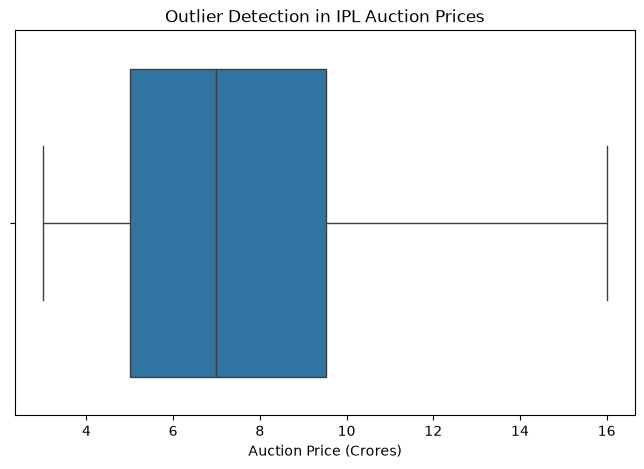

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(x=auction["PRICE(In crore Indian Rupees) "])

plt.title("Outlier Detection in IPL Auction Prices")
plt.xlabel("Auction Price (Crores)")
plt.show()

In [16]:
price_col = "PRICE(In crore Indian Rupees) "

Q1 = auction[price_col].quantile(0.25)
Q3 = auction[price_col].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = auction[
    (auction[price_col] < lower_limit) |
    (auction[price_col] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

display(outliers[["PLAYER", price_col, "YEAR"]])

Q1: 5.0
Q3: 9.525
IQR: 4.525
Lower limit: -1.7875000000000005
Upper limit: 16.3125
Number of potential outliers: 0


,PLAYER,PRICE(In crore Indian Rupees),YEAR


In [17]:
auction_clean.to_csv("Auction_Cleaned.csv", index=False)
matches_processed.to_csv("Matches_Cleaned.csv", index=False)

print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!
